# CassavaNet: building and comparing cassava leaf disease models
**War Child Canada | West Nile cassava monitoring**

Three models are compared on the same photos:
1. **Base**: the EfficientNet-B0, 512 px.
2. **CassavaNet (ours)**: EfficientNet-B0 trained here, 384 px.
3. **Ensemble**: the average of 1 and 2.

**Runtime should be changed to GPU**

Accept the Kaggle competition rules first: https://www.kaggle.com/c/cassava-leaf-disease-classification


**Time:** about 1 hour for training.


In [2]:
# for older keras
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
%pip install -q tf_keras kagglehub

In [3]:
import json, glob, re, random, time, warnings, zipfile, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import cv2
from PIL import Image
from IPython.display import display
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, f1_score,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
warnings.filterwarnings('ignore')

# ------------------------------ CONFIG ------------------------------
SEED = 42
IMG_SIZE_CN = 384          # CassavaNet input size (the original uses 512)
BATCH_SIZE = 32
EPOCHS_HEAD, EPOCHS_FINE = 2, 14
LR_HEAD, LR_FINE = 1e-3, 3e-4
CLASS_WEIGHT_POWER = 0.5   # 0 = none, 1 = fully balanced, 0.5 = softened
RETRAIN = False            # True = train CassavaNet again even if a saved copy exists
GUARD_ACC_DROP = 0.03      # recommendation ignores models more than 3 points less accurate than the best (see section 11)
USE_DRIVE = True           # save outputs to Google Drive so a Colab reset cannot delete them
CONF_THRESHOLD = 0.60      # below this the app asks for a new photo
HEALTHY_MIN_CONF = 0.80    # 'Healthy' needs higher confidence, because false reassurance is the worst error
# --------------------------------------------------------------------
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
CLASS_SHORT = ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']
FULL = {'CBB': 'Cassava Bacterial Blight', 'CBSD': 'Cassava Brown Streak Disease',
        'CGM': 'Cassava Green Mite / Mottle', 'CMD': 'Cassava Mosaic Disease', 'Healthy': 'Healthy'}

OUT_DIR = '/content/outputs'
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive'); OUT_DIR = '/content/drive/MyDrive/cassavanet_outputs'
    except Exception as e:
        print('Drive not mounted, saving to the session only:', repr(e)[:100])
METRICS_DIR = os.path.join(OUT_DIR, 'metrics')
os.makedirs(METRICS_DIR, exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
import tf_keras
print('TF', tf.__version__, '| tf_keras', tf_keras.__version__, '| GPUs:', gpus, '| outputs ->', OUT_DIR)
if gpus: keras.mixed_precision.set_global_policy('mixed_float16')
else: print('WARNING: no GPU. Training will be extremely slow.')

Mounted at /content/drive
TF 2.21.0 | tf_keras 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | outputs -> /content/drive/MyDrive/cassavanet_outputs


## 1. Download the Kaggle data

In [4]:
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [6]:
cassava_path = kagglehub.competition_download('cassava-leaf-disease-classification')
directory = next(r for r, d, f in os.walk(cassava_path) if 'train.csv' in f)
print('Data folder:', directory)
for name in sorted(os.listdir(directory)):
    p = os.path.join(directory, name)
    if os.path.isdir(p): print(f'  [folder] {name:30s} {len(os.listdir(p)):>7} files')
    else: print(f'  [file]   {name:30s} {os.path.getsize(p)/1e3:>9.1f} KB')

100%|██████████| 5.76G/5.76G [01:18<00:00, 79.0MB/s]

Extracting files...


Data folder: /root/.cache/kagglehub/competitions/cassava-leaf-disease-classification
  [file]   label_num_to_disease_map.json        0.2 KB
  [file]   sample_submission.csv                0.0 KB
  [folder] test_images                          1 files
  [folder] test_tfrecords                       1 files
  [file]   train.csv                          358.3 KB
  [folder] train_images                     21397 files
  [folder] train_tfrecords                     16 files


## 2. Dataset structure
What the files contain, whether anything is missing, and how the classes are balanced. (The `test_images` folder is only a tiny placeholder, so all evaluation uses `train_images`.)

train.csv shape: (21397, 2)
image_id    object
label        int64
Missing values: 0 | all image files present: True


,image_id,label,label_name
0,1000015157.jpg,0,Cassava Bacterial Blight (CBB)
1,1000201771.jpg,3,Cassava Mosaic Disease (CMD)
2,100042118.jpg,1,Cassava Brown Streak Disease (CBSD)
3,1000723321.jpg,1,Cassava Brown Streak Disease (CBSD)
4,1000812911.jpg,3,Cassava Mosaic Disease (CMD)


,class,photos,% of data
label,,,
0,Cassava Bacterial Blight (CBB),1087,5.1
1,Cassava Brown Streak Disease (CBSD),2189,10.2
2,Cassava Green Mottle (CGM),2386,11.2
3,Cassava Mosaic Disease (CMD),13158,61.5
4,Healthy,2577,12.0


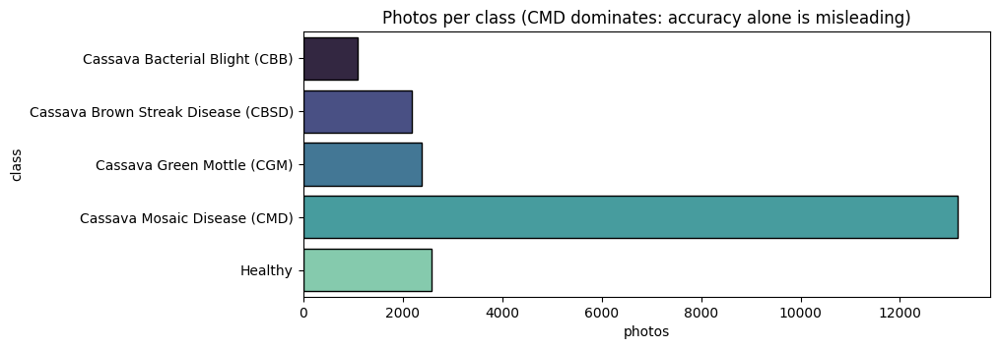

In [7]:
with open(os.path.join(directory, 'label_num_to_disease_map.json')) as f:
    mapping = {int(k): v for k, v in json.load(f).items()}
df = pd.read_csv(os.path.join(directory, 'train.csv'))      # ORDER MATTERS: do not shuffle (section 3 relies on it)
df['label_name'] = df.label.map(mapping)
df['path'] = df.image_id.map(lambda x: os.path.join(directory, 'train_images', x))

print('train.csv shape:', df[['image_id', 'label']].shape); print(df[['image_id', 'label']].dtypes.to_string())
print('Missing values:', int(df[['image_id', 'label']].isna().sum().sum()),
      '| all image files present:', bool(df.path.map(os.path.exists).all()))
display(df[['image_id', 'label', 'label_name']].head())

tab = df.label.value_counts().sort_index().rename('photos').to_frame()
tab.insert(0, 'class', [mapping[i] for i in tab.index]); tab['% of data'] = (tab.photos / len(df) * 100).round(1)
display(tab)
plt.figure(figsize=(9, 3.5)); sns.barplot(y=tab['class'], x=tab.photos, palette='mako', edgecolor='black')
plt.title('Photos per class (CMD dominates: accuracy alone is misleading)'); plt.show()

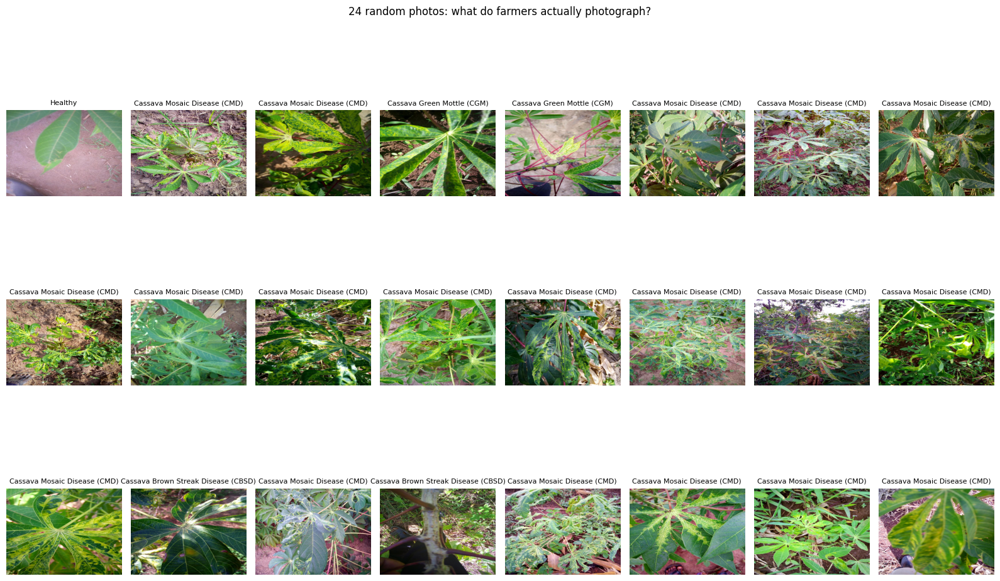

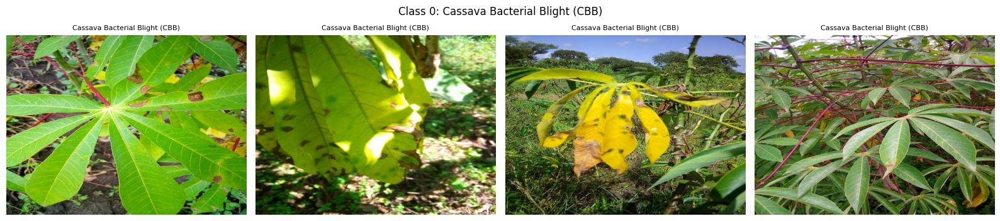

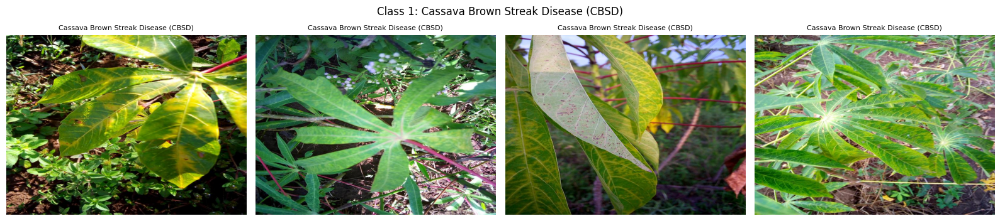

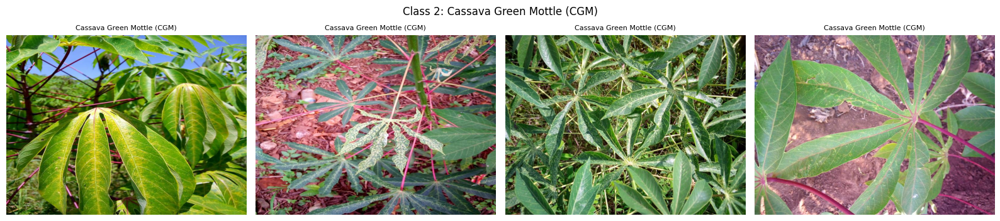

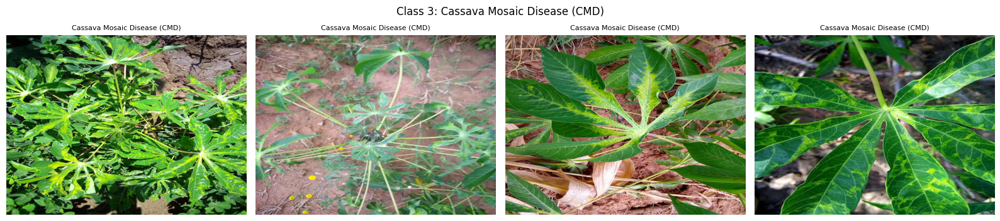

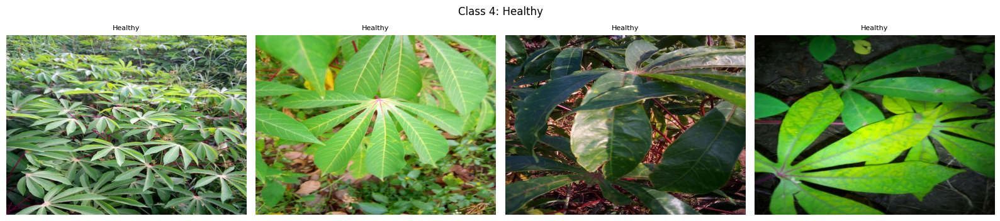

In [8]:
def load(path): return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def gallery(sub, n=8, title='', cols=4, show='label_name'):
    sub = sub.sample(min(n, len(sub)), random_state=None)
    rows = int(np.ceil(len(sub) / cols)); plt.figure(figsize=(16, 3.6 * rows))
    for i, (p, t) in enumerate(zip(sub.path, sub[show])):
        plt.subplot(rows, cols, i + 1); plt.imshow(load(p)); plt.axis('off'); plt.title(str(t), fontsize=8)
    plt.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

gallery(df, n=24, cols=8, title='24 random photos: what do farmers actually photograph?')
for c in sorted(mapping): gallery(df[df.label == c], n=4, title=f'Class {c}: {mapping[c]}')

Green fraction: median 0.64, share below 0.2: 2.8%


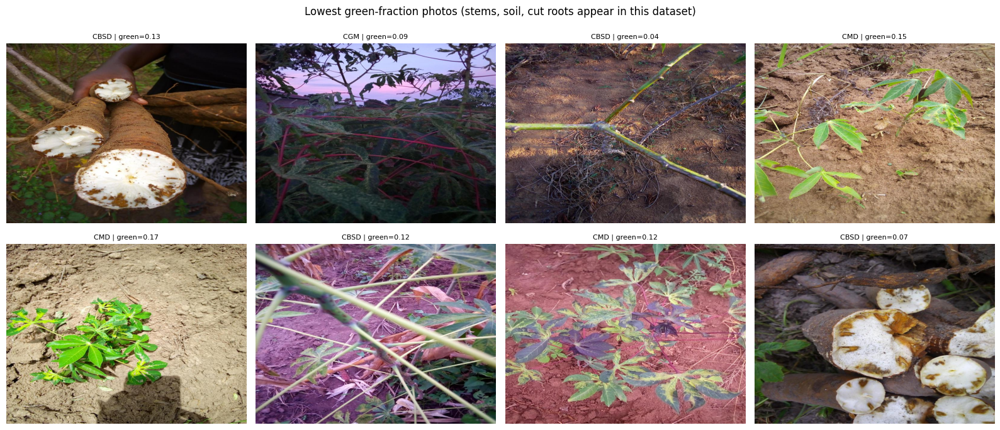

Image sizes (h, w): {(600, 800): 100}


In [9]:
# Not every photo is a clean leaf. Low 'green fraction' flags photos dominated by soil, stems, hands or cut roots.
def green_fraction(path):
    hsv = cv2.cvtColor(cv2.resize(cv2.imread(path), (200, 150)), cv2.COLOR_BGR2HSV)
    return float(((hsv[..., 0] >= 25) & (hsv[..., 0] <= 90) & (hsv[..., 1] >= 40) & (hsv[..., 2] >= 40)).mean())
probe = df.sample(400, random_state=1).copy(); probe['green'] = probe.path.map(green_fraction)
probe['info'] = probe.apply(lambda r: f"{r.label_name.split('(')[-1].strip(')')} | green={r.green:.2f}", axis=1)
print('Green fraction: median %.2f, share below 0.2: %.1f%%' % (probe.green.median(), 100 * (probe.green < 0.2).mean()))
gallery(probe.nsmallest(8, 'green'), n=8, title='Lowest green-fraction photos (stems, soil, cut roots appear in this dataset)', show='info')
im = [cv2.imread(p).shape[:2] for p in probe.path[:100]]
print('Image sizes (h, w):', pd.Series(im).value_counts().head(3).to_dict())

## 3. Train / validation / test design (fair for all three models)
The base model was trained with Keras `validation_split=0.2`, which uses the **first 20% of `train.csv`** as validation and the other 80% for training. So:
* **Test set = the first 20% of rows (4,279 photos)**: the base never trained on them. CassavaNet never sees them either.
* **CassavaNet trains only on the other 80%** (the original's own training pool), split 90/10 (stratified) into train and validation for early stopping.


In [10]:
n_test = int(0.2 * len(df))
test_df = df.iloc[:n_test].reset_index(drop=True)
pool_df = df.iloc[n_test:].reset_index(drop=True)
train_df, val_df = train_test_split(pool_df, test_size=0.1, stratify=pool_df.label, random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
y_test = test_df.label.values

split = pd.DataFrame({'TEST (shared)': test_df.label.value_counts().sort_index(),
                      'CassavaNet train': train_df.label.value_counts().sort_index(),
                      'CassavaNet val': val_df.label.value_counts().sort_index()})
split.index = CLASS_SHORT; split.loc['TOTAL'] = split.sum()
display(split)
print('Class mix, test vs whole data (%):'); display((pd.DataFrame({'test': test_df.label.value_counts(normalize=True).sort_index() * 100,
      'all data': df.label.value_counts(normalize=True).sort_index() * 100}).round(1)).set_axis(CLASS_SHORT))

,TEST (shared),CassavaNet train,CassavaNet val
CBB,200,798,89
CBSD,436,1578,175
CGM,495,1702,189
CMD,2638,9468,1052
Healthy,510,1860,207
TOTAL,4279,15406,1712


Class mix, test vs whole data (%):


,test,all data
CBB,4.7,5.1
CBSD,10.2,10.2
CGM,11.6,11.2
CMD,61.6,61.5
Healthy,11.9,12.0


## 4. Helpers: photo loading, farmer advice, and the photo-upload test

In [11]:
AUTOTUNE = tf.data.AUTOTUNE
RESAMPLE = getattr(Image, 'Resampling', Image).LANCZOS

def make_ds(paths, labels, size, method='bilinear', train=False, batch=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.asarray(labels, dtype='int32')))
    if train: ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    def _load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        return tf.cast(tf.image.resize(img, (size, size), method=method), tf.float32), y   # 0..255
    return ds.map(_load, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)

def prep_upload(img):
    # Phone photos are far larger than the 800x600 training photos: shrink first so fine detail is not lost.
    img = img.convert('RGB')
    if max(img.size) > 1000: img.thumbnail((800, 800), RESAMPLE)
    return img

ADVICE = {
 'CBB': ["Cut out and burn or bury affected plants and prunings now; do not leave them in or near the garden.",
         "Plant only clean cuttings from healthy gardens, and wash knives and hoes with soap or bleach between plants.",
         "Avoid working in the garden when leaves are wet, and rotate with a non-host crop such as beans or maize next season."],
 'CBSD': ["Uproot and destroy affected plants early; roots can rot even when leaves look fine, so check the roots of neighbouring plants.",
          "Replant only clean cuttings of CBSD-tolerant varieties from a trusted multiplier (ask NaCRRI / your extension officer).",
          "Whiteflies spread it: do not share or sell cuttings from this garden, and ask an extension officer to inspect nearby gardens."],
 'CGM': ["Check shoot tips and the underside of young leaves for tiny green mites, and ask your extension officer to confirm (it can look like a virus).",
         "Do not take cuttings from badly affected plants; plant at the start of the rains and choose tolerant varieties.",
         "Avoid spraying: it kills the natural enemies of the mite; keep the garden weeded and watch the dry-season spread."],
 'CMD': ["Uproot affected plants early and burn or bury them; never use their stems as cuttings.",
         "Replant with clean, CMD-resistant varieties from a trusted multiplier.",
         "Whiteflies spread CMD: inspect the garden every two weeks and remove new sick plants quickly."],
 'Healthy': ["No disease was found on this leaf; keep inspecting every two weeks, especially young shoots.",
             "Take cuttings only from plants with no yellow patches or streaks on leaves or stems.",
             "One leaf cannot show the stems or roots: if growth is poor or stems show brown streaks, ask your extension officer."],
 'Retake': ["The model is not sure about this photo.",
            "Retake it in daylight: one whole leaf, flat and in focus, without hands or soil covering it.",
            "If the plant still looks unhealthy, show it to your extension officer."],
}

def recommend(idx, conf):
    if conf < CONF_THRESHOLD or (idx == 4 and conf < HEALTHY_MIN_CONF): key = 'Retake'
    else: key = CLASS_SHORT[idx]
    return key, ADVICE[key]

def show_diagnosis(img, probs, title='', true=None):
    idx, conf = int(probs.argmax()), float(probs.max()); key, adv = recommend(idx, conf)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 1.2]})
    ax[0].imshow(img); ax[0].axis('off'); ax[0].set_title(title, fontsize=9)
    ax[1].barh(CLASS_SHORT, probs, color='seagreen'); ax[1].set_xlim(0, 1); ax[1].invert_yaxis()
    ax[1].set_title(f'Top answer: {CLASS_SHORT[idx]} ({conf:.0%})' + (f' | true: {CLASS_SHORT[true]}' if true is not None else ''))
    plt.tight_layout(); plt.show()
    print('RESULT:', 'Not sure: please retake the photo' if key == 'Retake' else ('Healthy' if key == 'Healthy' else 'Likely ' + FULL[key]))
    for i, line in enumerate(adv, 1): print(f'  {i}. {line}')
    print('  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)')
    print('-' * 95)

def test_my_photos(prob_fn, model_name):
    from google.colab import files
    for fn in files.upload():
        try: img = prep_upload(Image.open(fn))
        except Exception as e: print('Cannot open', fn, repr(e)[:100]); continue
        show_diagnosis(img, prob_fn(img), title=f'{model_name}: {fn}')
print('helpers ready')

helpers ready


## 5. Base Model: load it, check it, test it with your own photo
Source: https://github.com/Josh-robins/Cassava-Leaf-Disease-Classification/blob/main/model/EffNetB0_512_16.h5

In [12]:
ORIG_URL = 'https://github.com/Josh-robins/Cassava-Leaf-Disease-Classification/raw/refs/heads/main/model/EffNetB0_512_16.h5'
ORIG_PATH = '/content/EffNetB0_512_16.h5'
if not os.path.exists(ORIG_PATH): urllib.request.urlretrieve(ORIG_URL, ORIG_PATH)
print('Size: %.1f MB (expect about 47) | valid HDF5: %s' % (os.path.getsize(ORIG_PATH) / 1e6, open(ORIG_PATH, 'rb').read(8) == b'\x89HDF\r\n\x1a\n'))

def load_original(path):
    try:
        m = keras.models.load_model(path, compile=False); print('Loaded as a full model'); return m
    except Exception as e:
        print('Full-model load failed:', repr(e)[:250], '\nRebuilding the architecture and loading weights...')
    base = keras.applications.EfficientNetB0(include_top=False, weights=None, input_shape=(512, 512, 3))
    m = keras.Model(base.input, layers.Dense(5, activation='softmax', dtype='float32')(layers.GlobalAveragePooling2D()(base.output)))
    m.load_weights(path); print('Loaded weights into the rebuilt architecture'); return m

model_orig = load_original(ORIG_PATH)
ORIG_SIZE = model_orig.input_shape[1] or 512
print('input', model_orig.input_shape, '| output', model_orig.output_shape, '| %d parameters' % model_orig.count_params())

def probs_original(img):
    arr = np.array(prep_upload(img))
    x = tf.cast(tf.image.resize(arr, (ORIG_SIZE, ORIG_SIZE), method='nearest'), tf.float32)[None]   # as in its training
    return model_orig.predict(x, verbose=0)[0]

Size: 49.5 MB (expect about 47) | valid HDF5: True
Loaded as a full model
input (None, 512, 512, 3) | output (None, 5) | 4055976 parameters


In [13]:
# Check of the design assumption: if the original trained on the pool and not on the test photos,
# it should score a little HIGHER on pool photos than on test photos.
a, b = test_df.sample(1500, random_state=0), pool_df.sample(1500, random_state=0)
def acc_on(d):
    p = model_orig.predict(make_ds(d.path, d.label, ORIG_SIZE, method='nearest'), verbose=0).argmax(1)
    return float((p == d.label.values).mean())
acc_test, acc_pool = acc_on(a), acc_on(b)
print(f'Original model accuracy on 1,500 TEST photos: {acc_test:.3f} | on 1,500 POOL (its training) photos: {acc_pool:.3f}')
print('Reading:', 'consistent with the assumption (higher on its training pool).' if acc_pool - acc_test >= 0.015 else
      'gap is small, so the assumption is NOT confirmed. Treat the original model\'s test scores with caution.')

Original model accuracy on 1,500 TEST photos: 0.881 | on 1,500 POOL (its training) photos: 0.907
Reading: consistent with the assumption (higher on its training pool).


Saving 007_1617105868776.jpg to 007_1617105868776.jpg


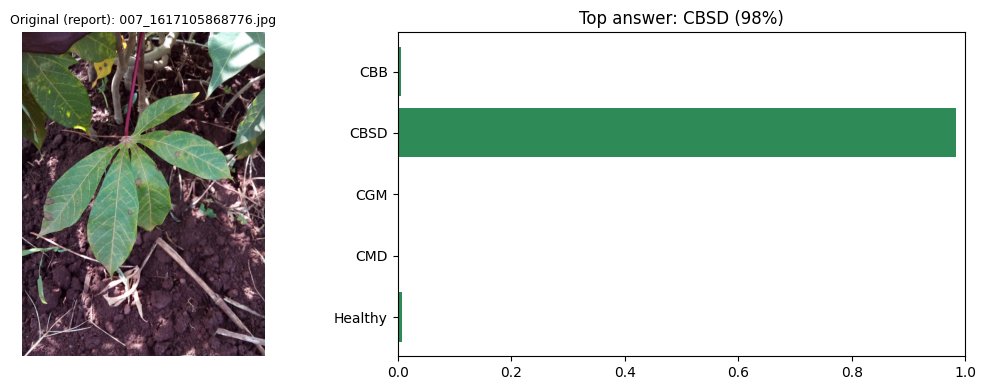

RESULT: Likely Cassava Brown Streak Disease
  1. Uproot and destroy affected plants early; roots can rot even when leaves look fine, so check the roots of neighbouring plants.
  2. Replant only clean cuttings of CBSD-tolerant varieties from a trusted multiplier (ask NaCRRI / your extension officer).
  3. Whiteflies spread it: do not share or sell cuttings from this garden, and ask an extension officer to inspect nearby gardens.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


In [16]:
# UPLOAD TEST 1: your photo -> ORIGINAL model
test_my_photos(probs_original, 'Original (report)')

## 6. CassavaNet: train (or load) and save
EfficientNet-B0 from ImageNet weights. Changes versus the earlier notebook: a short 2-epoch head warm-up, a higher fine-tuning rate (3e-4), gentler augmentation with `nearest` edge filling like the original, and a 384 px input.

define the augmentation


In [17]:
#  augmentation pipeline (only active during training)
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1, fill_mode='nearest'),                  # about +/- 36 degrees
    layers.RandomZoom(0.15, fill_mode='nearest'),
    layers.RandomTranslation(0.1, 0.1, fill_mode='nearest'),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name='augment')
print('augmentation pipeline ready')

augmentation pipeline ready


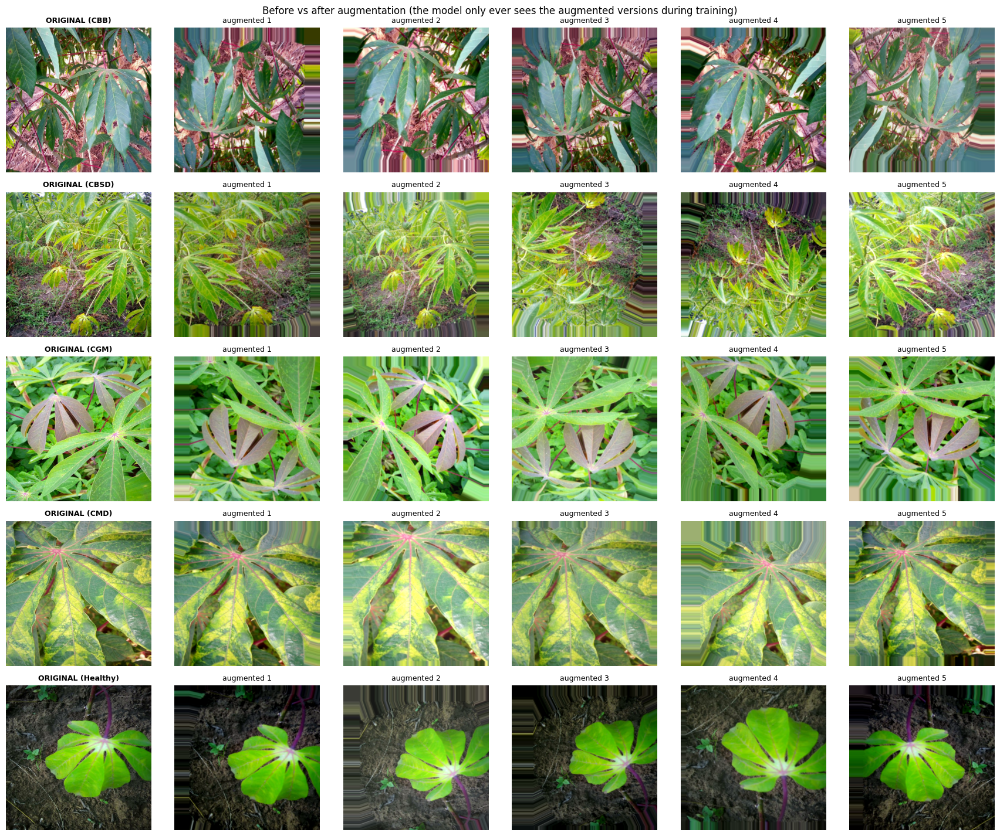

In [18]:
# one photo per class, the original on the left, then 5 different random augmentations of it
sample_rows = train_df.groupby('label').sample(1, random_state=7).sort_values('label')
n_aug = 5
fig, ax = plt.subplots(len(sample_rows), n_aug + 1, figsize=(2.9 * (n_aug + 1), 2.9 * len(sample_rows)))
for r, (_, row) in enumerate(sample_rows.iterrows()):
    img = tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(row.path), channels=3), (IMG_SIZE_CN, IMG_SIZE_CN))
    ax[r, 0].imshow(img.numpy().astype('uint8'))
    ax[r, 0].set_title(f'ORIGINAL ({CLASS_SHORT[int(row.label)]})', fontsize=9, fontweight='bold')
    for c in range(1, n_aug + 1):
        aug = augment(img[None], training=True)[0].numpy().clip(0, 255).astype('uint8')
        ax[r, c].imshow(aug); ax[r, c].set_title(f'augmented {c}', fontsize=9)
for a in ax.flat: a.axis('off')
plt.suptitle('Before vs after augmentation (the model only ever sees the augmented versions during training)', fontsize=12)
plt.tight_layout(); plt.show()

In [19]:
# CELL 3: build CassavaNet, then STAGE 1: train only the new classifier head (base frozen)
keras.mixed_precision.set_global_policy('float32')   # mixed precision breaks EfficientNet in legacy Keras

CN_PATH = os.path.join(OUT_DIR, 'cassavanet_b0_%d.keras' % IMG_SIZE_CN)
model_cn, history_cn, loaded_from_disk = None, None, False

if os.path.exists(CN_PATH) and not RETRAIN:
    model_cn = keras.models.load_model(CN_PATH, compile=False); loaded_from_disk = True
    print('Loaded saved CassavaNet:', CN_PATH, '| stages 1 and 2 are skipped (set RETRAIN = True to train again)')
else:
    cw = compute_class_weight('balanced', classes=np.arange(5), y=train_df.label.values) ** CLASS_WEIGHT_POWER
    class_weight = {i: float(w) for i, w in enumerate(cw)}
    print('Class weights:', {CLASS_SHORT[i]: round(w, 2) for i, w in class_weight.items()})
    train_ds = make_ds(train_df.path, train_df.label, IMG_SIZE_CN, train=True)
    val_ds = make_ds(val_df.path, val_df.label, IMG_SIZE_CN)

    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(IMG_SIZE_CN, IMG_SIZE_CN, 3))
    inp = keras.Input((IMG_SIZE_CN, IMG_SIZE_CN, 3))
    x = base(augment(inp), training=False)                    # BatchNorm stays in inference mode
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
    model_cn = keras.Model(inp, layers.Dense(5, activation='softmax', dtype='float32')(x), name='cassavanet_b0')

    def compile_(lr):
        model_cn.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                         loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    base.trainable = False; compile_(LR_HEAD)
    h1 = model_cn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=class_weight)
    print('Stage 1 done in %.1f min. Check val_accuracy before running Cell 4.' % ((time.time() - t0) / 60))

Loaded saved CassavaNet: /content/drive/MyDrive/cassavanet_outputs/cassavanet_b0_384.keras | stages 1 and 2 are skipped (set RETRAIN = True to train again)


In [20]:
# CELL 4: STAGE 2: fine-tune the whole network at a lower learning rate, then save. Needs Cell 3 to have run.
if loaded_from_disk:
    print('Skipped: CassavaNet was loaded from disk.')
else:
    t1 = time.time()
    base.trainable = True
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False   # keep BatchNorm frozen
    compile_(LR_FINE)

    cbs = [keras.callbacks.ModelCheckpoint(os.path.join(OUT_DIR, 'cassavanet_best.weights.h5'), save_best_only=True,
                                           save_weights_only=True, monitor='val_loss', mode='min'),
           keras.callbacks.EarlyStopping(monitor='val_loss', min_delta=0.001, patience=4, mode='min',
                                         restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_delta=0.001,
                                             mode='min', verbose=1)]
    h2 = model_cn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, class_weight=class_weight, callbacks=cbs)
    history_cn = {k: h1.history[k] + h2.history[k] for k in h1.history}
    model_cn.save(CN_PATH)
    print('Stage 2 done in %.1f min | saved to %s' % ((time.time() - t1) / 60, CN_PATH))

def probs_cassavanet(img):                      # used by the upload tests and the ensemble
    arr = np.array(prep_upload(img))
    return model_cn.predict(tf.image.resize(arr, (IMG_SIZE_CN, IMG_SIZE_CN))[None], verbose=0)[0]

Skipped: CassavaNet was loaded from disk.


In [21]:
if history_cn:
    ep = range(1, len(history_cn['loss']) + 1); fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
    a1.plot(ep, history_cn['accuracy'], 'go-', label='Train'); a1.plot(ep, history_cn['val_accuracy'], 'ro-', label='Validation')
    a1.axvline(EPOCHS_HEAD + 0.5, ls='--', c='gray'); a1.set_title('Accuracy (dashed = fine-tuning starts)'); a1.legend()
    a2.plot(ep, history_cn['loss'], 'go-', label='Train'); a2.plot(ep, history_cn['val_loss'], 'ro-', label='Validation')
    a2.axvline(EPOCHS_HEAD + 0.5, ls='--', c='gray'); a2.set_title('Loss'); a2.legend(); plt.suptitle('CassavaNet'); plt.show()
    pd.DataFrame(history_cn).to_csv(os.path.join(METRICS_DIR, 'cassavanet_training_history.csv'), index=False)
    print('Original report for reference: best validation accuracy about 0.883 (a different validation set).')
else:
    print('CassavaNet was loaded from disk, so there is no training history in this session.')

CassavaNet was loaded from disk, so there is no training history in this session.


Saving 007_1617105868776.jpg to 007_1617105868776 (1).jpg


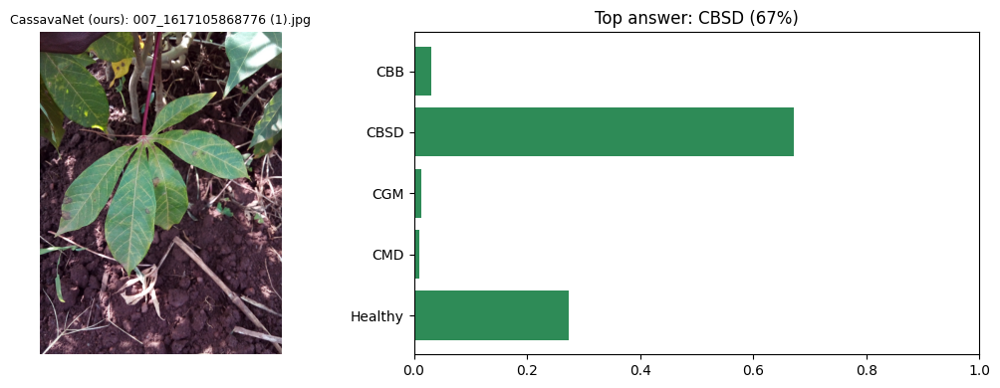

RESULT: Likely Cassava Brown Streak Disease
  1. Uproot and destroy affected plants early; roots can rot even when leaves look fine, so check the roots of neighbouring plants.
  2. Replant only clean cuttings of CBSD-tolerant varieties from a trusted multiplier (ask NaCRRI / your extension officer).
  3. Whiteflies spread it: do not share or sell cuttings from this garden, and ask an extension officer to inspect nearby gardens.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


In [22]:
# UPLOAD TEST 2: your photo -> CASSAVANET
test_my_photos(probs_cassavanet, 'CassavaNet (ours)')

## 7. Evaluation tools
Per model: 5-class confusion matrix (counts and %), one-vs-rest **TP / TN / FP / FN** for each class (as % of all photos and as rates), the farmer-safety view **diseased vs healthy**, ROC and precision-recall curves. Everything is saved to `METRICS_DIR`.

**Diseased vs healthy view** (positive = diseased): TP diseased called diseased | **FN diseased called HEALTHY (the dangerous error)** | FP healthy called diseased | TN healthy called healthy.

In [23]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); a = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - a) / d, (c + a) / d)

def ovr_table(y, pred):
    N, rows = len(y), []
    for i, c in enumerate(CLASS_SHORT):
        t, p = (y == i), (pred == i)
        TP, FN, FP, TN = int((t & p).sum()), int((t & ~p).sum()), int((~t & p).sum()), int((~t & ~p).sum())
        rows.append({'class': c, 'TP': TP, 'FN': FN, 'FP': FP, 'TN': TN,
                     'TP % of photos': 100 * TP / N, 'FN % of photos': 100 * FN / N, 'FP % of photos': 100 * FP / N, 'TN % of photos': 100 * TN / N,
                     'sensitivity (TP rate) %': 100 * TP / max(TP + FN, 1), 'specificity (TN rate) %': 100 * TN / max(TN + FP, 1),
                     'precision %': 100 * TP / max(TP + FP, 1), 'miss rate (FN rate) %': 100 * FN / max(TP + FN, 1),
                     'false alarm rate (FP rate) %': 100 * FP / max(TN + FP, 1)})
    return pd.DataFrame(rows).set_index('class').round(2)

def sick_vs_healthy(y, pred):
    sick, ps, N = (y != 4), (pred != 4), len(y)
    TP, FN, FP, TN = int((sick & ps).sum()), int((sick & ~ps).sum()), int((~sick & ps).sum()), int((~sick & ~ps).sum())
    ds, hs = max(TP + FN, 1), max(FP + TN, 1)
    tbl = pd.DataFrame({'meaning': ['diseased, called diseased', 'diseased, called HEALTHY (dangerous)', 'healthy, called diseased', 'healthy, called healthy'],
                        'photos': [TP, FN, FP, TN], '% of all photos': [100 * v / N for v in (TP, FN, FP, TN)],
                        '% of its group': [100 * TP / ds, 100 * FN / ds, 100 * FP / hs, 100 * TN / hs]}, index=['TP', 'FN', 'FP', 'TN']).round(2)
    lo, hi = wilson(FN, TP + FN)
    return tbl, dict(diseased_total=TP + FN, diseased_called_healthy_n=FN, diseased_called_healthy_rate=FN / ds,
                     dch_ci_low=lo, dch_ci_high=hi, healthy_false_alarm_rate=FP / hs)

def plot_confusion(cm, ax, title):
    pct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    annot = np.array([[f'{cm[i, j]}\n{pct[i, j]:.1f}%' for j in range(5)] for i in range(5)])
    sns.heatmap(pct, annot=annot, fmt='', cmap='Greens', vmin=0, vmax=100, cbar=False, xticklabels=CLASS_SHORT, yticklabels=CLASS_SHORT, ax=ax)
    ax.set_title(title, fontsize=10); ax.set_xlabel('Predicted'); ax.set_ylabel('True (row % = recall)')

def evaluate_model(name, y, probs, out_dir=METRICS_DIR, plot=True):
    os.makedirs(out_dir, exist_ok=True); slug = re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')
    pred, N, Y = probs.argmax(1), len(y), label_binarize(y, classes=np.arange(5))
    try: auc = roc_auc_score(Y, probs, average='macro')
    except ValueError: auc = np.nan
    cm = confusion_matrix(y, pred, labels=list(range(5))); ovr = ovr_table(y, pred); sv, svm = sick_vs_healthy(y, pred)
    rep = classification_report(y, pred, labels=list(range(5)), target_names=CLASS_SHORT, digits=3, zero_division=0)
    m = dict(model=name, n_photos=N, accuracy=accuracy_score(y, pred),
             macro_f1=f1_score(y, pred, average='macro', labels=list(range(5)), zero_division=0), macro_auc=auc)
    for i, c in enumerate(CLASS_SHORT): m[f'recall_{c}'] = cm[i, i] / max(cm[i].sum(), 1)
    m.update(svm)
    print(f"\n=========== {name} ===========\nAccuracy {m['accuracy']:.4f} | Macro-F1 {m['macro_f1']:.4f} | Macro ROC-AUC {auc:.4f}")
    print(rep); print('One-vs-rest TP / TN / FP / FN per class:'); display(ovr)
    print('Farmer-safety view (diseased vs healthy):'); display(sv)
    print(f"Diseased called Healthy: {svm['diseased_called_healthy_n']} of {svm['diseased_total']} "
          f"= {100*svm['diseased_called_healthy_rate']:.1f}% (95% CI {100*svm['dch_ci_low']:.1f} to {100*svm['dch_ci_high']:.1f}%)")
    if plot:
        fig, ax = plt.subplots(1, 3, figsize=(20, 5.5)); plot_confusion(cm, ax[0], f'{name}: confusion matrix')
        for i, c in enumerate(CLASS_SHORT):
            if Y[:, i].sum() == 0 or Y[:, i].sum() == N: continue
            fpr, tpr, _ = roc_curve(Y[:, i], probs[:, i]); ax[1].plot(fpr, tpr, label=f'{c} (AUC {roc_auc_score(Y[:, i], probs[:, i]):.3f})')
            p, r, _ = precision_recall_curve(Y[:, i], probs[:, i]); ax[2].plot(r, p, label=f'{c} (AP {average_precision_score(Y[:, i], probs[:, i]):.3f})')
        ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC (one-vs-rest)'); ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend()
        ax[2].set_title('Precision-Recall'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend()
        plt.tight_layout(); fig.savefig(os.path.join(out_dir, f'{slug}_curves.png'), dpi=120); plt.show()
    pd.DataFrame(cm, index=CLASS_SHORT, columns=CLASS_SHORT).to_csv(os.path.join(out_dir, f'{slug}_confusion_counts.csv'))
    ovr.to_csv(os.path.join(out_dir, f'{slug}_tp_tn_fp_fn_per_class.csv')); sv.to_csv(os.path.join(out_dir, f'{slug}_diseased_vs_healthy.csv'))
    open(os.path.join(out_dir, f'{slug}_classification_report.txt'), 'w').write(rep)
    return dict(metrics=m, ovr=ovr, sick=sv, cm=cm)
print('evaluation tools ready')

evaluation tools ready


## 8. Evaluate Original and CassavaNet on the shared test set


=========== Original (report) ===========
Accuracy 0.8752 | Macro-F1 0.7734 | Macro ROC-AUC 0.9699
              precision    recall  f1-score   support

         CBB      0.600     0.630     0.615       200
        CBSD      0.792     0.787     0.789       436
         CGM      0.877     0.723     0.793       495
         CMD      0.960     0.956     0.958      2638
     Healthy      0.658     0.775     0.712       510

    accuracy                          0.875      4279
   macro avg      0.778     0.774     0.773      4279
weighted avg      0.881     0.875     0.876      4279

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,126,74,84,3995,2.94,1.73,1.96,93.36,63.00,97.94,60.00,37.00,2.06
CBSD,343,93,90,3753,8.02,2.17,2.10,87.71,78.67,97.66,79.21,21.33,2.34
CGM,358,137,50,3734,8.37,3.20,1.17,87.26,72.32,98.68,87.75,27.68,1.32
CMD,2523,115,105,1536,58.96,2.69,2.45,35.90,95.64,93.60,96.00,4.36,6.40
Healthy,395,115,205,3564,9.23,2.69,4.79,83.29,77.45,94.56,65.83,22.55,5.44


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",3564,83.29,94.56
FN,"diseased, called HEALTHY (dangerous)",205,4.79,5.44
FP,"healthy, called diseased",115,2.69,22.55
TN,"healthy, called healthy",395,9.23,77.45


Diseased called Healthy: 205 of 3769 = 5.4% (95% CI 4.8 to 6.2%)


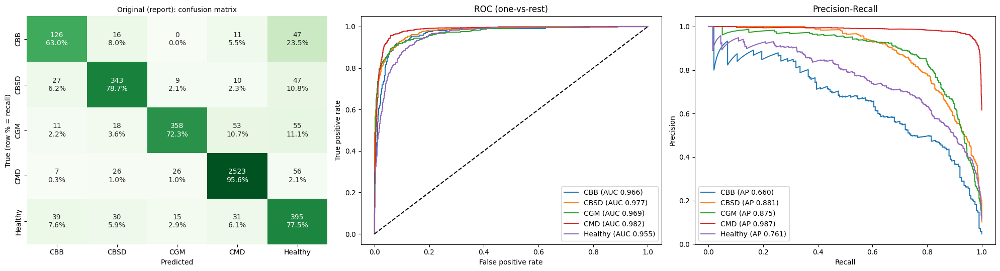

In [24]:
p_orig_test = model_orig.predict(make_ds(test_df.path, test_df.label, ORIG_SIZE, method='nearest'), verbose=0)
p_cn_test = model_cn.predict(make_ds(test_df.path, test_df.label, IMG_SIZE_CN), verbose=0)
results = {}
results['Original (report)'] = evaluate_model('Original (report)', y_test, p_orig_test)


=========== CassavaNet (ours) ===========
Accuracy 0.8572 | Macro-F1 0.7454 | Macro ROC-AUC 0.9611
              precision    recall  f1-score   support

         CBB      0.610     0.555     0.581       200
        CBSD      0.762     0.727     0.744       436
         CGM      0.859     0.723     0.785       495
         CMD      0.950     0.948     0.949      2638
     Healthy      0.603     0.747     0.667       510

    accuracy                          0.857      4279
   macro avg      0.757     0.740     0.745      4279
weighted avg      0.863     0.857     0.858      4279

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,111,89,71,4008,2.59,2.08,1.66,93.67,55.50,98.26,60.99,44.50,1.74
CBSD,317,119,99,3744,7.41,2.78,2.31,87.50,72.71,97.42,76.20,27.29,2.58
CGM,358,137,59,3725,8.37,3.20,1.38,87.05,72.32,98.44,85.85,27.68,1.56
CMD,2501,137,131,1510,58.45,3.20,3.06,35.29,94.81,92.02,95.02,5.19,7.98
Healthy,381,129,251,3518,8.90,3.01,5.87,82.22,74.71,93.34,60.28,25.29,6.66


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",3518,82.22,93.34
FN,"diseased, called HEALTHY (dangerous)",251,5.87,6.66
FP,"healthy, called diseased",129,3.01,25.29
TN,"healthy, called healthy",381,8.90,74.71


Diseased called Healthy: 251 of 3769 = 6.7% (95% CI 5.9 to 7.5%)


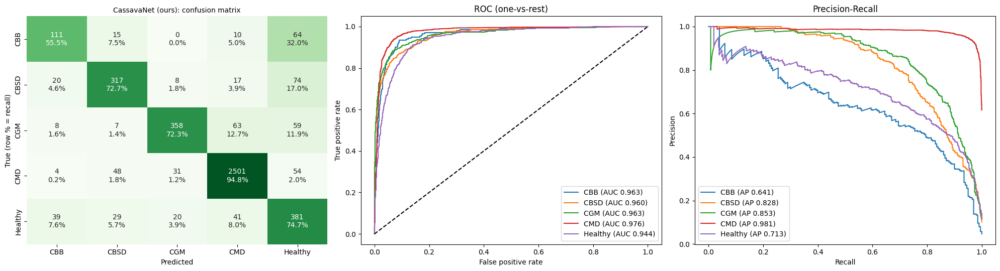

In [25]:
results['CassavaNet (ours)'] = evaluate_model('CassavaNet (ours)', y_test, p_cn_test)

In [26]:
# Head-to-head: the two single models
summary2 = pd.DataFrame([r['metrics'] for r in results.values()]).set_index('model')
cols = ['accuracy', 'macro_f1', 'macro_auc', 'recall_CBB', 'recall_CBSD', 'recall_CGM', 'recall_CMD', 'recall_Healthy', 'diseased_called_healthy_rate', 'healthy_false_alarm_rate']
display(summary2[cols].round(4).T)

model,Original (report),CassavaNet (ours)
accuracy,0.8752,0.8572
macro_f1,0.7734,0.7454
macro_auc,0.9699,0.9611
recall_CBB,0.6300,0.5550
recall_CBSD,0.7867,0.7271
recall_CGM,0.7232,0.7232
recall_CMD,0.9564,0.9481
recall_Healthy,0.7745,0.7471
diseased_called_healthy_rate,0.0544,0.0666
healthy_false_alarm_rate,0.2255,0.2529


## 9. Ensemble (average of Original and CassavaNet)


=========== Ensemble (average) ===========
Accuracy 0.8752 | Macro-F1 0.7731 | Macro ROC-AUC 0.9694
              precision    recall  f1-score   support

         CBB      0.612     0.615     0.613       200
        CBSD      0.808     0.773     0.790       436
         CGM      0.880     0.725     0.795       495
         CMD      0.958     0.958     0.958      2638
     Healthy      0.649     0.780     0.709       510

    accuracy                          0.875      4279
   macro avg      0.781     0.770     0.773      4279
weighted avg      0.880     0.875     0.876      4279

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,123,77,78,4001,2.87,1.80,1.82,93.50,61.50,98.09,61.19,38.50,1.91
CBSD,337,99,80,3763,7.88,2.31,1.87,87.94,77.29,97.92,80.82,22.71,2.08
CGM,359,136,49,3735,8.39,3.18,1.15,87.29,72.53,98.71,87.99,27.47,1.29
CMD,2528,110,112,1529,59.08,2.57,2.62,35.73,95.83,93.17,95.76,4.17,6.83
Healthy,398,112,215,3554,9.30,2.62,5.02,83.06,78.04,94.30,64.93,21.96,5.70


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",3554,83.06,94.30
FN,"diseased, called HEALTHY (dangerous)",215,5.02,5.70
FP,"healthy, called diseased",112,2.62,21.96
TN,"healthy, called healthy",398,9.30,78.04


Diseased called Healthy: 215 of 3769 = 5.7% (95% CI 5.0 to 6.5%)


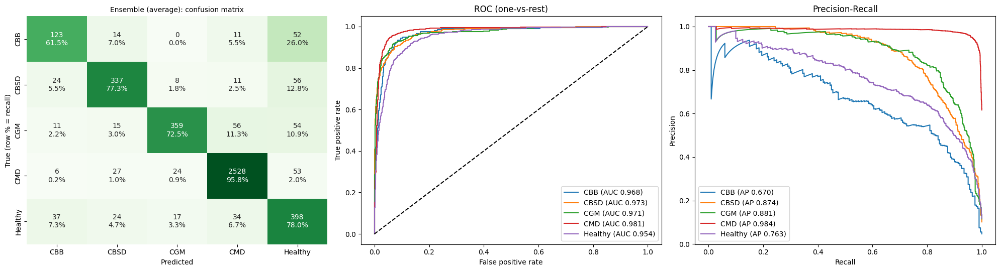

In [27]:
p_ens_test = (p_orig_test + p_cn_test) / 2
def probs_ensemble(img): return (probs_original(img) + probs_cassavanet(img)) / 2
results['Ensemble (average)'] = evaluate_model('Ensemble (average)', y_test, p_ens_test)

Saving 003_1617105852257.jpg to 003_1617105852257.jpg


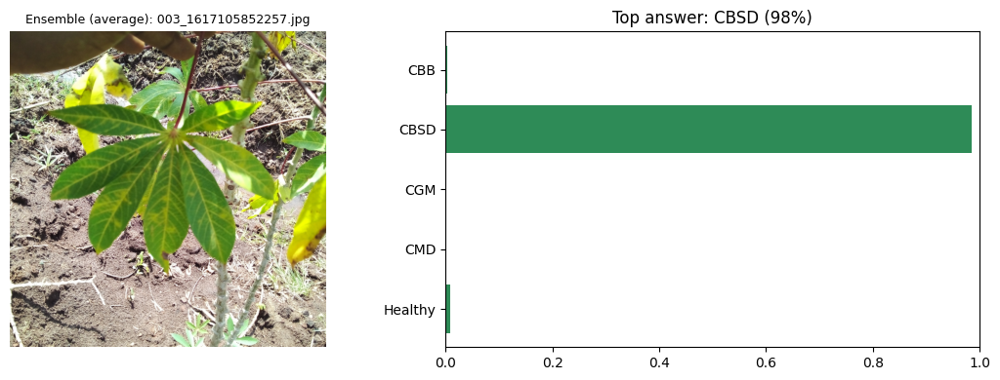

RESULT: Likely Cassava Brown Streak Disease
  1. Uproot and destroy affected plants early; roots can rot even when leaves look fine, so check the roots of neighbouring plants.
  2. Replant only clean cuttings of CBSD-tolerant varieties from a trusted multiplier (ask NaCRRI / your extension officer).
  3. Whiteflies spread it: do not share or sell cuttings from this garden, and ask an extension officer to inspect nearby gardens.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


In [28]:
# UPLOAD TEST 3: your photo -> ENSEMBLE
test_my_photos(probs_ensemble, 'Ensemble (average)')

## 10. Compare all three

model,Original (report),CassavaNet (ours),Ensemble (average)
accuracy,0.8752,0.8572,0.8752
macro_f1,0.7734,0.7454,0.7731
macro_auc,0.9699,0.9611,0.9694
recall_CBB,0.6300,0.5550,0.6150
recall_CBSD,0.7867,0.7271,0.7729
recall_CGM,0.7232,0.7232,0.7253
recall_CMD,0.9564,0.9481,0.9583
recall_Healthy,0.7745,0.7471,0.7804
diseased_called_healthy_rate,0.0544,0.0666,0.0570
healthy_false_alarm_rate,0.2255,0.2529,0.2196


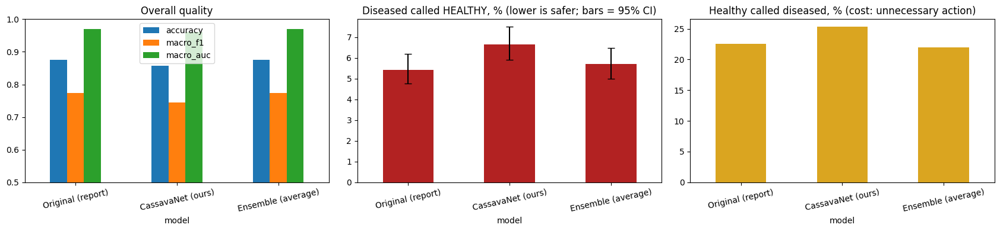

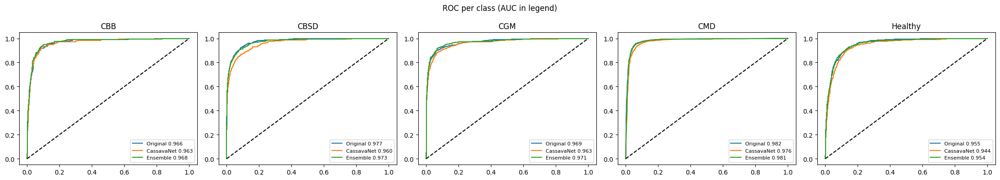

In [30]:
summary = pd.DataFrame([r['metrics'] for r in results.values()]).set_index('model')
display(summary[cols].round(4).T)
summary.round(5).to_csv(os.path.join(METRICS_DIR, 'model_comparison.csv'))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
summary[['accuracy', 'macro_f1', 'macro_auc']].plot.bar(ax=ax[0], rot=12, ylim=(0.5, 1)); ax[0].set_title('Overall quality')
rate = summary.diseased_called_healthy_rate * 100
err = [rate - summary.dch_ci_low * 100, summary.dch_ci_high * 100 - rate]
rate.plot.bar(ax=ax[1], rot=12, color='firebrick', yerr=err, capsize=4); ax[1].set_title('Diseased called HEALTHY, % (lower is safer; bars = 95% CI)')
(summary.healthy_false_alarm_rate * 100).plot.bar(ax=ax[2], rot=12, color='goldenrod'); ax[2].set_title('Healthy called diseased, % (cost: unnecessary action)')
plt.tight_layout(); plt.show()

Y = label_binarize(y_test, classes=np.arange(5)); P = {'Original': p_orig_test, 'CassavaNet': p_cn_test, 'Ensemble (average)': p_ens_test}
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for i, c in enumerate(CLASS_SHORT):
    for k, v in P.items():
        fpr, tpr, _ = roc_curve(Y[:, i], v[:, i]); ax[i].plot(fpr, tpr, label=f'{k.split(" (")[0]} {roc_auc_score(Y[:, i], v[:, i]):.3f}')
    ax[i].plot([0, 1], [0, 1], 'k--'); ax[i].set_title(c); ax[i].legend(fontsize=8)
plt.suptitle('ROC per class (AUC in legend)'); plt.tight_layout(); fig.savefig(os.path.join(METRICS_DIR, 'roc_all_models.png'), dpi=120); plt.show()

## 11. Recommendation and your choice
**Rule (your choice: safety first):** recommend the model with the **lowest share of diseased plants called Healthy**, among models whose overall accuracy is within `GUARD_ACC_DROP` of the best. The guard stops a model that simply cries "disease" at everything from winning. If the confidence intervals of two models overlap, the difference may be noise, so macro-F1 is shown as the tie-breaker.

In [31]:
best_acc = summary.accuracy.max()
elig = summary[summary.accuracy >= best_acc - GUARD_ACC_DROP]
order = elig.sort_values(['diseased_called_healthy_rate', 'macro_f1'], ascending=[True, False])
recommended = order.index[0]
show = summary[['accuracy', 'macro_f1', 'diseased_called_healthy_rate', 'dch_ci_low', 'dch_ci_high', 'healthy_false_alarm_rate']].copy()
show['eligible'] = show.index.isin(elig.index); display(show.round(4))
print(f'RECOMMENDED: {recommended}')
print(f"  Calls {100*summary.loc[recommended,'diseased_called_healthy_rate']:.1f}% of diseased plants Healthy "
      f"(95% CI {100*summary.loc[recommended,'dch_ci_low']:.1f} to {100*summary.loc[recommended,'dch_ci_high']:.1f}%), accuracy {summary.loc[recommended,'accuracy']:.3f}.")
for o in order.index[1:]:
    overlap = summary.loc[o, 'dch_ci_low'] <= summary.loc[recommended, 'dch_ci_high'] and summary.loc[recommended, 'dch_ci_low'] <= summary.loc[o, 'dch_ci_high']
    print(f"  vs {o}: " + ('confidence intervals OVERLAP, so the safety gap may be noise; compare macro-F1 and your own photos too.' if overlap else 'clearly different on safety.'))
print('Pick the final model in the next cell (the dropdown). "recommended" uses the line above.')

,accuracy,macro_f1,diseased_called_healthy_rate,dch_ci_low,dch_ci_high,healthy_false_alarm_rate,eligible
model,,,,,,,
Original (report),0.8752,0.7734,0.0544,0.0476,0.0621,0.2255,True
CassavaNet (ours),0.8572,0.7454,0.0666,0.0591,0.0750,0.2529,True
Ensemble (average),0.8752,0.7731,0.0570,0.0501,0.0649,0.2196,True


RECOMMENDED: Original (report)
  Calls 5.4% of diseased plants Healthy (95% CI 4.8 to 6.2%), accuracy 0.875.
  vs Ensemble (average): confidence intervals OVERLAP, so the safety gap may be noise; compare macro-F1 and your own photos too.
  vs CassavaNet (ours): confidence intervals OVERLAP, so the safety gap may be noise; compare macro-F1 and your own photos too.
Pick the final model in the next cell (the dropdown). "recommended" uses the line above.


In [34]:
CHOSEN = "recommended" #@param ["recommended", "Original (report)", "CassavaNet (ours)", "Ensemble (average)"]
CONF_THRESHOLD = 0.6 #@param {type:"slider", min:0.4, max:0.9, step:0.05}
HEALTHY_MIN_CONF = 0.8 #@param {type:"slider", min:0.5, max:0.95, step:0.05}

chosen_name = recommended if CHOSEN == 'recommended' else CHOSEN
PROB_FN = {'Original (report)': probs_original, 'CassavaNet (ours)': probs_cassavanet, 'Ensemble (average)': probs_ensemble}
probs_chosen = PROB_FN[chosen_name]
print('Final model:', chosen_name)

# Safety rule check on the test set: 'Healthy' must be confident, otherwise ask for a new photo
# Fix key mismatch between P and chosen_name
p_key = 'Original' if chosen_name == 'Original (report)' else ('CassavaNet' if chosen_name == 'CassavaNet (ours)' else chosen_name)
pc = P[p_key]; pred, conf = pc.argmax(1), pc.max(1); sick = (y_test != 4)
flag = (pred == 4) & (conf < HEALTHY_MIN_CONF)
before, after = int((sick & (pred == 4)).sum()), int((sick & (pred == 4) & ~flag).sum())
print(f'Diseased photos called Healthy: {before} before the rule, {after} after (rule asks for a new photo when Healthy confidence < {HEALTHY_MIN_CONF:.2f}).')
print(f'Cost: {int((~sick & flag).sum())} genuinely healthy photos would also be sent for a retake.')
rows = []
for t in (0.5, 0.6, 0.7, 0.8, 0.9):
    k = conf >= t; rows.append({'confidence threshold': t, 'photos answered %': 100 * k.mean(), 'accuracy on answered %': 100 * (pred[k] == y_test[k]).mean()})
display(pd.DataFrame(rows).round(1))

Final model: Original (report)
Diseased photos called Healthy: 205 before the rule, 58 after (rule asks for a new photo when Healthy confidence < 0.80).
Cost: 151 genuinely healthy photos would also be sent for a retake.


,confidence threshold,photos answered %,accuracy on answered %
0,0.5,95.6,89.6
1,0.6,90.8,91.3
2,0.7,85.6,93.0
3,0.8,78.8,95.1
4,0.9,70.1,96.9


## 12. Final demo with the chosen model

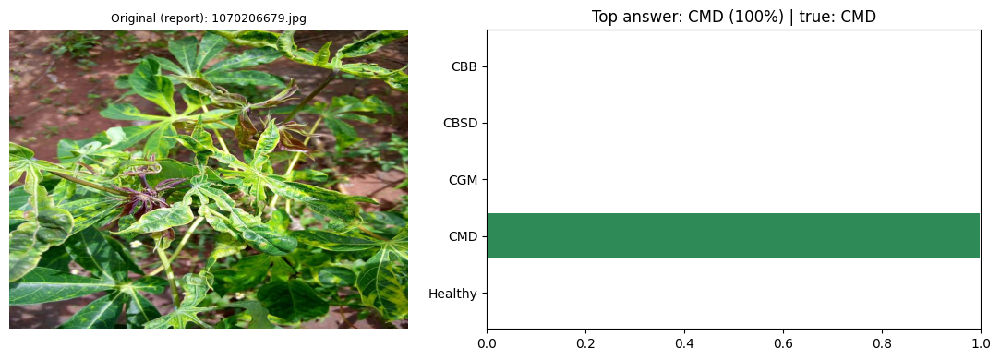

RESULT: Likely Cassava Mosaic Disease
  1. Uproot affected plants early and burn or bury them; never use their stems as cuttings.
  2. Replant with clean, CMD-resistant varieties from a trusted multiplier.
  3. Whiteflies spread CMD: inspect the garden every two weeks and remove new sick plants quickly.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


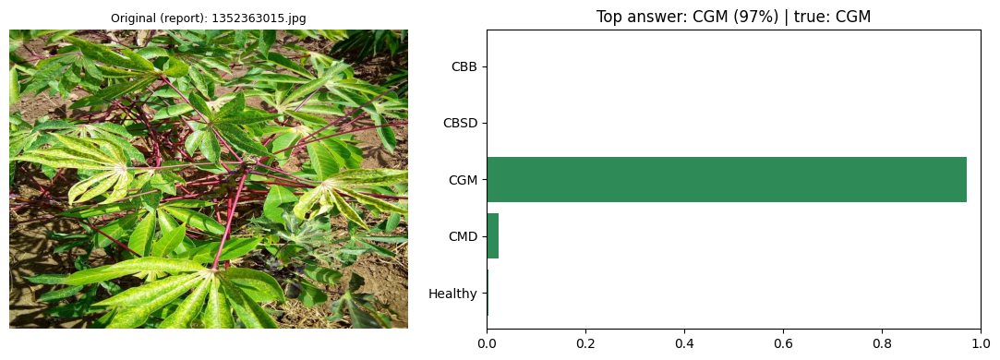

RESULT: Likely Cassava Green Mite / Mottle
  1. Check shoot tips and the underside of young leaves for tiny green mites, and ask your extension officer to confirm (it can look like a virus).
  2. Do not take cuttings from badly affected plants; plant at the start of the rains and choose tolerant varieties.
  3. Avoid spraying: it kills the natural enemies of the mite; keep the garden weeded and watch the dry-season spread.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


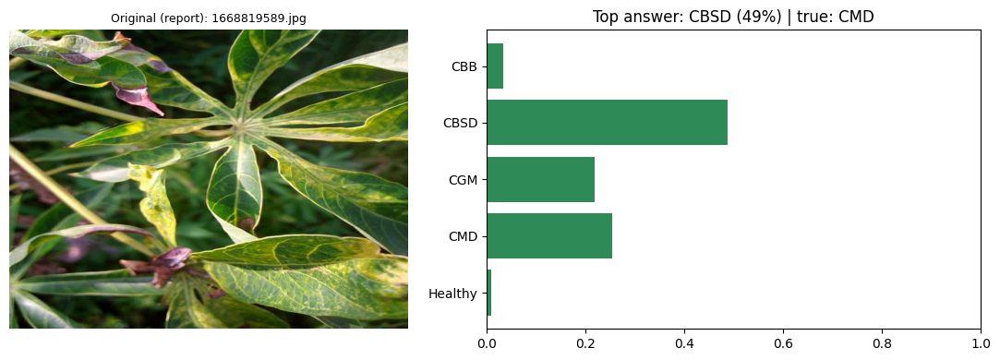

RESULT: Not sure: please retake the photo
  1. The model is not sure about this photo.
  2. Retake it in daylight: one whole leaf, flat and in focus, without hands or soil covering it.
  3. If the plant still looks unhealthy, show it to your extension officer.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


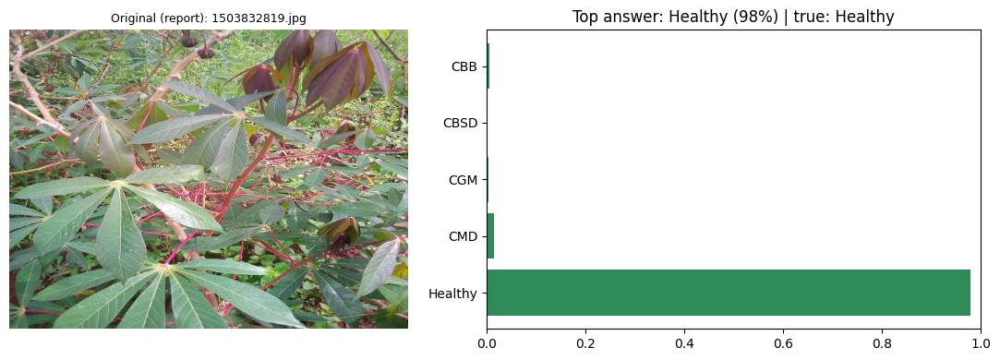

RESULT: Healthy
  1. No disease was found on this leaf; keep inspecting every two weeks, especially young shoots.
  2. Take cuttings only from plants with no yellow patches or streaks on leaves or stems.
  3. One leaf cannot show the stems or roots: if growth is poor or stems show brown streaks, ask your extension officer.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


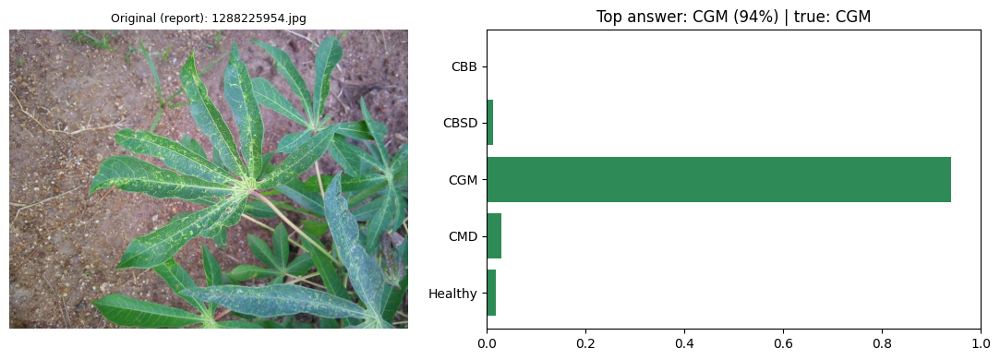

RESULT: Likely Cassava Green Mite / Mottle
  1. Check shoot tips and the underside of young leaves for tiny green mites, and ask your extension officer to confirm (it can look like a virus).
  2. Do not take cuttings from badly affected plants; plant at the start of the rains and choose tolerant varieties.
  3. Avoid spraying: it kills the natural enemies of the mite; keep the garden weeded and watch the dry-season spread.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


In [36]:
for _, r in test_df.sample(5, random_state=3).iterrows():
    img = Image.open(r.path); show_diagnosis(img, probs_chosen(img), title=f'{chosen_name}: {r.image_id}', true=int(r.label))

Saving 003_1617105852257.jpg to 003_1617105852257 (1).jpg


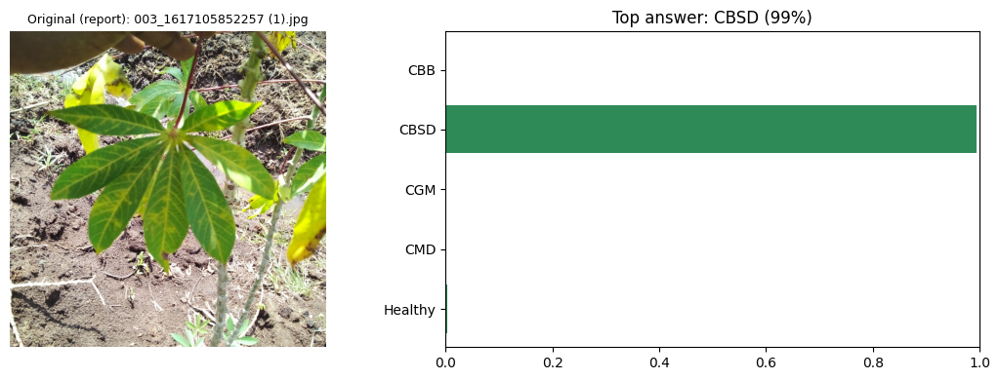

RESULT: Likely Cassava Brown Streak Disease
  1. Uproot and destroy affected plants early; roots can rot even when leaves look fine, so check the roots of neighbouring plants.
  2. Replant only clean cuttings of CBSD-tolerant varieties from a trusted multiplier (ask NaCRRI / your extension officer).
  3. Whiteflies spread it: do not share or sell cuttings from this garden, and ask an extension officer to inspect nearby gardens.
  (Screening aid only: it sees one leaf photo, not stems or roots. When in doubt, ask your extension officer.)
-----------------------------------------------------------------------------------------------


In [37]:
# Your own photos with the CHOSEN model
test_my_photos(probs_chosen, chosen_name)

Saving 008_1617105878531.jpg to 008_1617105878531.jpg


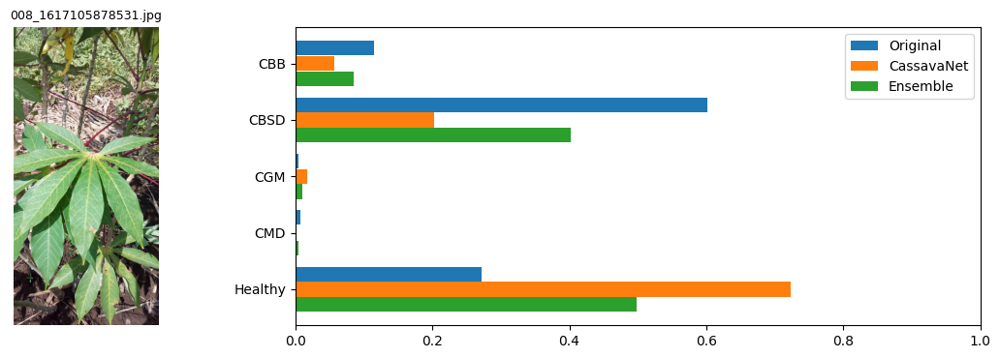

008_1617105878531.jpg -> {'Original': 'CBSD 60%', 'CassavaNet': 'Healthy 72%', 'Ensemble': 'Healthy 50%'}


In [38]:
# Side-by-side: your photo through all three models (useful when they disagree, e.g. CBSD vs CMD)
from google.colab import files
for fn in files.upload():
    img = prep_upload(Image.open(fn)); po, pcn = probs_original(img), probs_cassavanet(img); pe = (po + pcn) / 2
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.5]}); ax[0].imshow(img); ax[0].axis('off'); ax[0].set_title(fn, fontsize=9)
    y_ = np.arange(5)
    for off, (k, p, c) in zip((-0.27, 0, 0.27), (('Original', po, 'tab:blue'), ('CassavaNet', pcn, 'tab:orange'), ('Ensemble', pe, 'tab:green'))):
        ax[1].barh(y_ + off, p, 0.26, label=k, color=c)
    ax[1].set_yticks(y_); ax[1].set_yticklabels(CLASS_SHORT); ax[1].invert_yaxis(); ax[1].set_xlim(0, 1); ax[1].legend(); plt.tight_layout(); plt.show()
    print(fn, '->', {k: f'{CLASS_SHORT[int(p.argmax())]} {p.max():.0%}' for k, p in (('Original', po), ('CassavaNet', pcn), ('Ensemble', pe))})

## 13. Optional: test on YOUR OWN labeled photos (the real test for West Nile)
Make a **.zip** with one folder per class, named exactly `CBB`, `CBSD`, `CGM`, `CMD`, `Healthy`, each holding JPG/PNG photos whose label an agronomist has confirmed. Run the cell and upload the zip. Even 100 to 300 photos tell us far more about field performance than the Kaggle test set does.

Saving cassava images.zip to cassava images.zip
label
CBSD       50
CMD        50
Healthy    50

=========== LOCAL Original (report) ===========
Accuracy 0.8800 | Macro-F1 0.5369 | Macro ROC-AUC nan
              precision    recall  f1-score   support

         CBB      0.000     0.000     0.000         0
        CBSD      0.929     0.780     0.848        50
         CGM      0.000     0.000     0.000         0
         CMD      1.000     0.920     0.958        50
     Healthy      0.825     0.940     0.879        50

    accuracy                          0.880       150
   macro avg      0.551     0.528     0.537       150
weighted avg      0.918     0.880     0.895       150

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,0,0,4,146,0.00,0.00,2.67,97.33,0.0,97.33,0.00,0.0,2.67
CBSD,39,11,3,97,26.00,7.33,2.00,64.67,78.0,97.00,92.86,22.0,3.00
CGM,0,0,1,149,0.00,0.00,0.67,99.33,0.0,99.33,0.00,0.0,0.67
CMD,46,4,0,100,30.67,2.67,0.00,66.67,92.0,100.00,100.00,8.0,0.00
Healthy,47,3,10,90,31.33,2.00,6.67,60.00,94.0,90.00,82.46,6.0,10.00


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",90,60.00,90.0
FN,"diseased, called HEALTHY (dangerous)",10,6.67,10.0
FP,"healthy, called diseased",3,2.00,6.0
TN,"healthy, called healthy",47,31.33,94.0


Diseased called Healthy: 10 of 100 = 10.0% (95% CI 5.5 to 17.4%)


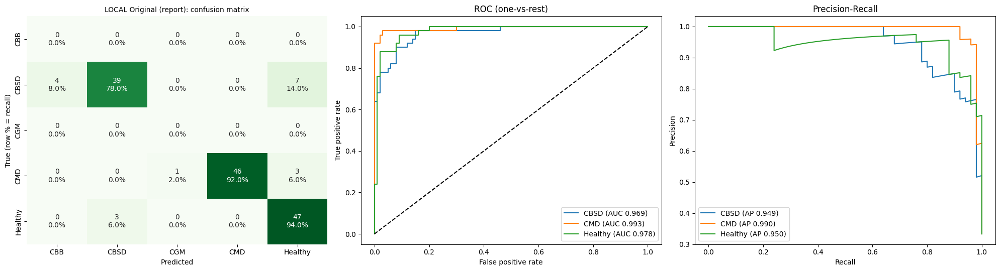


=========== LOCAL CassavaNet (ours) ===========
Accuracy 0.8133 | Macro-F1 0.4919 | Macro ROC-AUC nan
              precision    recall  f1-score   support

         CBB      0.000     0.000     0.000         0
        CBSD      0.964     0.540     0.692        50
         CGM      0.000     0.000     0.000         0
         CMD      1.000     0.900     0.947        50
     Healthy      0.694     1.000     0.820        50

    accuracy                          0.813       150
   macro avg      0.532     0.488     0.492       150
weighted avg      0.886     0.813     0.820       150

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,0,0,3,147,0.00,0.00,2.00,98.00,0.0,98.00,0.00,0.0,2.00
CBSD,27,23,1,99,18.00,15.33,0.67,66.00,54.0,99.00,96.43,46.0,1.00
CGM,0,0,2,148,0.00,0.00,1.33,98.67,0.0,98.67,0.00,0.0,1.33
CMD,45,5,0,100,30.00,3.33,0.00,66.67,90.0,100.00,100.00,10.0,0.00
Healthy,50,0,22,78,33.33,0.00,14.67,52.00,100.0,78.00,69.44,0.0,22.00


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",78,52.00,78.0
FN,"diseased, called HEALTHY (dangerous)",22,14.67,22.0
FP,"healthy, called diseased",0,0.00,0.0
TN,"healthy, called healthy",50,33.33,100.0


Diseased called Healthy: 22 of 100 = 22.0% (95% CI 15.0 to 31.1%)


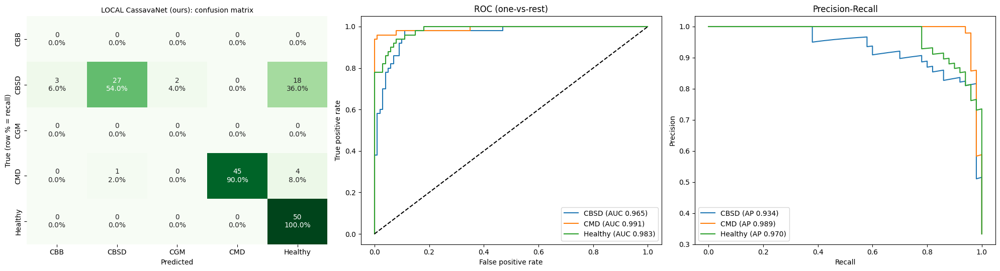


=========== LOCAL Ensemble (average) ===========
Accuracy 0.8667 | Macro-F1 0.5267 | Macro ROC-AUC nan
              precision    recall  f1-score   support

         CBB      0.000     0.000     0.000         0
        CBSD      0.947     0.720     0.818        50
         CGM      0.000     0.000     0.000         0
         CMD      1.000     0.920     0.958        50
     Healthy      0.774     0.960     0.857        50

    accuracy                          0.867       150
   macro avg      0.544     0.520     0.527       150
weighted avg      0.907     0.867     0.878       150

One-vs-rest TP / TN / FP / FN per class:


,TP,FN,FP,TN,TP % of photos,FN % of photos,FP % of photos,TN % of photos,sensitivity (TP rate) %,specificity (TN rate) %,precision %,miss rate (FN rate) %,false alarm rate (FP rate) %
class,,,,,,,,,,,,,
CBB,0,0,4,146,0.00,0.00,2.67,97.33,0.0,97.33,0.00,0.0,2.67
CBSD,36,14,2,98,24.00,9.33,1.33,65.33,72.0,98.00,94.74,28.0,2.00
CGM,0,0,0,150,0.00,0.00,0.00,100.00,0.0,100.00,0.00,0.0,0.00
CMD,46,4,0,100,30.67,2.67,0.00,66.67,92.0,100.00,100.00,8.0,0.00
Healthy,48,2,14,86,32.00,1.33,9.33,57.33,96.0,86.00,77.42,4.0,14.00


Farmer-safety view (diseased vs healthy):


,meaning,photos,% of all photos,% of its group
TP,"diseased, called diseased",86,57.33,86.0
FN,"diseased, called HEALTHY (dangerous)",14,9.33,14.0
FP,"healthy, called diseased",2,1.33,4.0
TN,"healthy, called healthy",48,32.00,96.0


Diseased called Healthy: 14 of 100 = 14.0% (95% CI 8.5 to 22.1%)


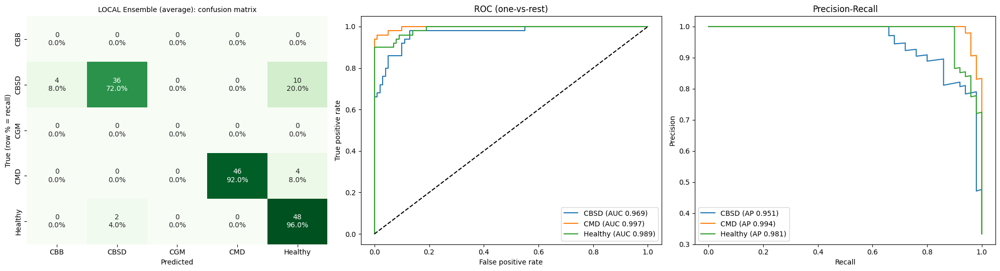

,n_photos,accuracy,macro_f1,diseased_called_healthy_rate,healthy_false_alarm_rate
model,,,,,
LOCAL Original (report),150,0.8800,0.5369,0.10,0.06
LOCAL CassavaNet (ours),150,0.8133,0.4919,0.22,0.00
LOCAL Ensemble (average),150,0.8667,0.5267,0.14,0.04


In [39]:
from google.colab import files
from PIL import ImageFile
# Allow Pillow to load truncated/broken images rather than crashing
ImageFile.LOAD_TRUNCATED_IMAGES = True

up = files.upload()
if up:
    zipfile.ZipFile(list(up)[0]).extractall('/content/local_photos')
    rows = [(p, i) for i, c in enumerate(CLASS_SHORT) for p in glob.glob(f'/content/local_photos/**/{c}/*', recursive=True) if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
    local = pd.DataFrame(rows, columns=['path', 'label']); print(local.label.map(lambda i: CLASS_SHORT[i]).value_counts().to_string())
    yl = local.label.values; PL = {}
    for k, fn in (('Original (report)', probs_original), ('CassavaNet (ours)', probs_cassavanet)):
        PL[k] = np.stack([fn(Image.open(p)) for p in local.path])
    PL['Ensemble (average)'] = (PL['Original (report)'] + PL['CassavaNet (ours)']) / 2
    local_res = {k: evaluate_model('LOCAL ' + k, yl, v, out_dir=os.path.join(METRICS_DIR, 'local_photos')) for k, v in PL.items()}
    display(pd.DataFrame([r['metrics'] for r in local_res.values()]).set_index('model')[['n_photos', 'accuracy', 'macro_f1', 'diseased_called_healthy_rate', 'healthy_false_alarm_rate']].round(4))

## 14. Save everything

In [40]:
out = test_df[['image_id', 'label']].copy(); out['true'] = out.label.map(lambda i: CLASS_SHORT[i])
for k, v in P.items():
    out[k + ' | pred'] = [CLASS_SHORT[i] for i in v.argmax(1)]; out[k + ' | confidence'] = v.max(1).round(4)
out.drop(columns='label').to_csv(os.path.join(METRICS_DIR, 'test_predictions.csv'), index=False)
cfg = dict(class_names=CLASS_SHORT, chosen_model=chosen_name, recommended_model=recommended, rule='fewest diseased called healthy, accuracy guard %.2f' % GUARD_ACC_DROP,
           conf_threshold=CONF_THRESHOLD, healthy_min_conf=HEALTHY_MIN_CONF, cassavanet_input=IMG_SIZE_CN, original_input=ORIG_SIZE,
           test_set='first 20%% of train.csv (%d photos)' % len(test_df), advice=ADVICE)
json.dump(cfg, open(os.path.join(OUT_DIR, 'config.json'), 'w'), indent=2)
json.dump(summary.reset_index().to_dict('records'), open(os.path.join(METRICS_DIR, 'metrics.json'), 'w'), indent=2, default=float)
for root, d, f in os.walk(OUT_DIR):
    for x in sorted(f): print(os.path.join(root, x).replace(OUT_DIR, '.'))

./cassavanet_b0_384.keras
./cassavanet_best.weights.h5
./config.json
./metrics/cassavanet_ours_classification_report.txt
./metrics/cassavanet_ours_confusion_counts.csv
./metrics/cassavanet_ours_curves.png
./metrics/cassavanet_ours_diseased_vs_healthy.csv
./metrics/cassavanet_ours_tp_tn_fp_fn_per_class.csv
./metrics/cassavanet_training_history.csv
./metrics/ensemble_average_classification_report.txt
./metrics/ensemble_average_confusion_counts.csv
./metrics/ensemble_average_curves.png
./metrics/ensemble_average_diseased_vs_healthy.csv
./metrics/ensemble_average_tp_tn_fp_fn_per_class.csv
./metrics/metrics.json
./metrics/model_comparison.csv
./metrics/original_report_classification_report.txt
./metrics/original_report_confusion_counts.csv
./metrics/original_report_curves.png
./metrics/original_report_diseased_vs_healthy.csv
./metrics/original_report_tp_tn_fp_fn_per_class.csv
./metrics/roc_all_models.png
./metrics/test_predictions.csv
./metrics/local_photos/local_cassavanet_ours_classificat